In [1]:
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "mnli"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9847
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['premise', 'hypothesis', 'label', 'idx'],
    num_rows: 392702
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation_matched'],
    "validation_mismatched": raw_datasets['validation_mismatched'],
    "test_matched": raw_datasets['test_matched'],
    "test_mismatched": raw_datasets['test_mismatched']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 392702
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9847
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'premise': 'Conceptually cream skimming has two basic dimensions - product and geography.',
 'hypothesis': 'Product and geography are what make cream skimming work. ',
 'label': 1,
 'idx': 0}

In [10]:
raw_train_dataset[5]['premise'], raw_train_dataset[5]['hypothesis']

("my walkman broke so i'm upset now i just have to turn the stereo up real loud",
 "I'm upset that my walkman broke and now I have to turn the stereo up really loud.")

In [11]:
raw_train_dataset[5]['label']

0

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'premise': Value('string'),
 'hypothesis': Value('string'),
 'label': ClassLabel(names=['entailment', 'neutral', 'contradiction']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["premise"], example["hypothesis"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

Map: 100%|██████████| 9847/9847 [00:00<00:00, 62787.32 examples/s]


DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 392702
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 9847
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["premise", "hypothesis", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [36]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

validation_mismatched = DataLoader(
    tokenized_datasets["validation_mismatched"], batch_size=32, collate_fn=data_collator
)

# eval_dataloader = DataLoader(
#     tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
# )

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 83]),
 'token_type_ids': torch.Size([32, 83]),
 'attention_mask': torch.Size([32, 83])}

# 4. Load Model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(1.1568, grad_fn=<NllLossBackward0>) torch.Size([32, 3])


In [25]:
outputs.keys()

odict_keys(['loss', 'logits', 'hidden_states', 'attentions'])

In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

In [27]:
len(outputs.hidden_states['hidden_states']), outputs.hidden_states['hidden_states'][0].shape

(13, torch.Size([32, 83, 768]))

In [28]:
len(outputs.attentions['attention_head'])

12

In [29]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 83, 83])

In [30]:
len(outputs.attentions["pre_wo"])

12

In [31]:
outputs.attentions["pre_wo"][0].shape

torch.Size([32, 83, 768])

In [32]:
outputs.attentions["attention_output"][0].shape

torch.Size([32, 83, 768])

### Loading Trained Weights

In [33]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [34]:
from train_eval_func import eval_loop

In [37]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.844727457972491}

# 5. Similarity Analysis

In [38]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [39]:
from CKA import SentenceCKARedundancy

headsCka_eval = SentenceCKARedundancy(device)

In [40]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

### Using Training Data on CLS Token only

In [41]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:53<00:00,  2.14it/s]

  Reps Similarity Stats:
    Average: 0.900543
    Highest: 0.950922
    Lowest:  0.815386

  Atts Similarity Stats:
    Average: 0.968208
    Highest: 0.995179
    Lowest:  0.902450
  MHA Similarity Stats:
    Average: 0.907499
    Highest: 0.958554
    Lowest:  0.802509
  Pre Wo Similarity Stats:
    Average: 0.788110
    Highest: 0.924360
    Lowest:  0.629840
  Sublayer Similarity Stats:
    Average: 0.938844
    Highest: 0.989434
    Lowest:  0.792756
  Pre Wo Sublayer Similarity Stats:
    Average: 0.847166
    Highest: 0.949206
    Lowest:  0.709287


In [42]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:38<00:00,  2.95it/s]

  Sub Out Similarity Stats:
    Average: 0.880749
    Highest: 0.989248
    Lowest:  0.669688


In [43]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

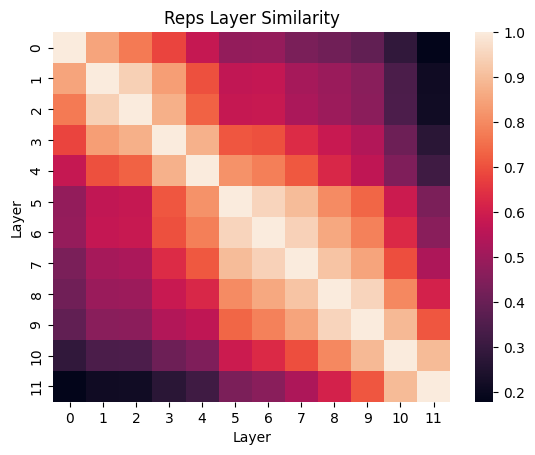

In [44]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [45]:
_,_ = adjacent_similarity_stats(reps_similarity)

Similarity Scores: [0.84995466, 0.9416882, 0.87238073, 0.8772004, 0.8153862, 0.9509218, 0.94495463, 0.91530186, 0.95017695, 0.89282155, 0.8951835]
Number of High Similar Pairs: 11


In [46]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.85)

Similarity Scores: [0.84995466, 0.9416882, 0.87238073, 0.8772004, 0.8153862, 0.9509218, 0.94495463, 0.91530186, 0.95017695, 0.89282155, 0.8951835]
Number of High Similar Pairs: 9


In [47]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.9)

Similarity Scores: [0.84995466, 0.9416882, 0.87238073, 0.8772004, 0.8153862, 0.9509218, 0.94495463, 0.91530186, 0.95017695, 0.89282155, 0.8951835]
Number of High Similar Pairs: 5


Text(50.722222222222214, 0.5, 'Layer')

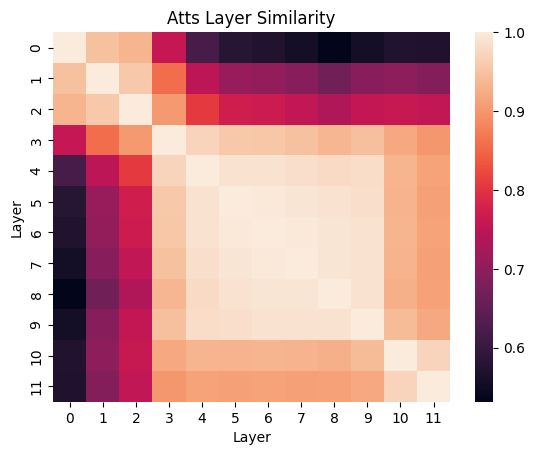

In [48]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [49]:
_,_ = adjacent_similarity_stats(atts_similarity)

Similarity Scores: [0.9480736, 0.95762366, 0.90244985, 0.97075725, 0.988331, 0.9951788, 0.99501306, 0.9918306, 0.9881822, 0.94064885, 0.9722001]
Number of High Similar Pairs: 11


In [50]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.85)

Similarity Scores: [0.9480736, 0.95762366, 0.90244985, 0.97075725, 0.988331, 0.9951788, 0.99501306, 0.9918306, 0.9881822, 0.94064885, 0.9722001]
Number of High Similar Pairs: 11


In [51]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.9)

Similarity Scores: [0.9480736, 0.95762366, 0.90244985, 0.97075725, 0.988331, 0.9951788, 0.99501306, 0.9918306, 0.9881822, 0.94064885, 0.9722001]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

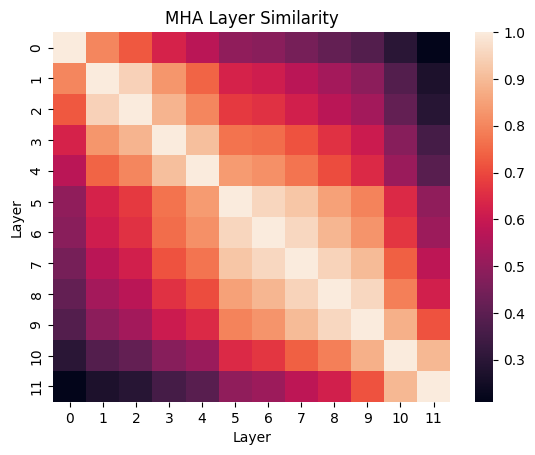

In [52]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [53]:
_,_ = adjacent_similarity_stats(mha_similarity)

Similarity Scores: [0.80250895, 0.94635814, 0.88878477, 0.91033113, 0.8373367, 0.9555839, 0.9583921, 0.9506075, 0.95855385, 0.8790223, 0.8950106]
Number of High Similar Pairs: 11


In [54]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.85)

Similarity Scores: [0.80250895, 0.94635814, 0.88878477, 0.91033113, 0.8373367, 0.9555839, 0.9583921, 0.9506075, 0.95855385, 0.8790223, 0.8950106]
Number of High Similar Pairs: 9


In [55]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.9)

Similarity Scores: [0.80250895, 0.94635814, 0.88878477, 0.91033113, 0.8373367, 0.9555839, 0.9583921, 0.9506075, 0.95855385, 0.8790223, 0.8950106]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

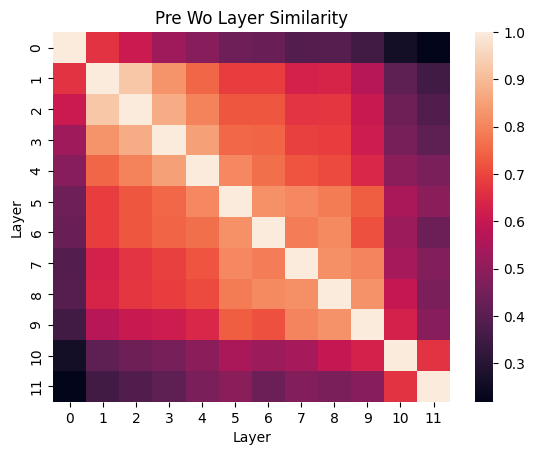

In [56]:
title = "Pre Wo Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [57]:
_,_ = adjacent_similarity_stats(pre_wo_similarity)

Similarity Scores: [0.6659843, 0.9243603, 0.87339586, 0.8491729, 0.8072975, 0.822238, 0.78849614, 0.81945986, 0.82354045, 0.6298398, 0.6654305]
Number of High Similar Pairs: 7


In [58]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.85)

Similarity Scores: [0.6659843, 0.9243603, 0.87339586, 0.8491729, 0.8072975, 0.822238, 0.78849614, 0.81945986, 0.82354045, 0.6298398, 0.6654305]
Number of High Similar Pairs: 2


In [59]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.9)

Similarity Scores: [0.6659843, 0.9243603, 0.87339586, 0.8491729, 0.8072975, 0.822238, 0.78849614, 0.81945986, 0.82354045, 0.6298398, 0.6654305]
Number of High Similar Pairs: 1


Text(50.722222222222214, 0.5, 'Layer')

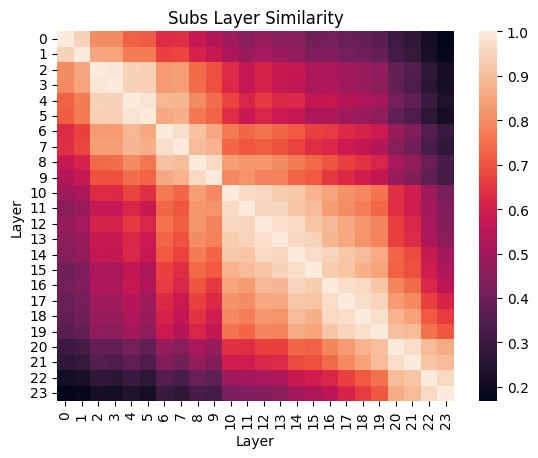

In [60]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [61]:
_,_ = adjacent_similarity_stats(sub_similarity)

Similarity Scores: [0.94622254, 0.8510667, 0.9894339, 0.94752693, 0.9835593, 0.8578636, 0.97204363, 0.8944833, 0.95911723, 0.7927564, 0.9611193, 0.9485187, 0.97666997, 0.956903, 0.96855277, 0.9286354, 0.9706192, 0.96965593, 0.97694975, 0.9000298, 0.970536, 0.9127014, 0.9584567]
Number of High Similar Pairs: 22


In [62]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.85)

Similarity Scores: [0.94622254, 0.8510667, 0.9894339, 0.94752693, 0.9835593, 0.8578636, 0.97204363, 0.8944833, 0.95911723, 0.7927564, 0.9611193, 0.9485187, 0.97666997, 0.956903, 0.96855277, 0.9286354, 0.9706192, 0.96965593, 0.97694975, 0.9000298, 0.970536, 0.9127014, 0.9584567]
Number of High Similar Pairs: 22


In [63]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.9)

Similarity Scores: [0.94622254, 0.8510667, 0.9894339, 0.94752693, 0.9835593, 0.8578636, 0.97204363, 0.8944833, 0.95911723, 0.7927564, 0.9611193, 0.9485187, 0.97666997, 0.956903, 0.96855277, 0.9286354, 0.9706192, 0.96965593, 0.97694975, 0.9000298, 0.970536, 0.9127014, 0.9584567]
Number of High Similar Pairs: 19


Text(50.722222222222214, 0.5, 'Layer')

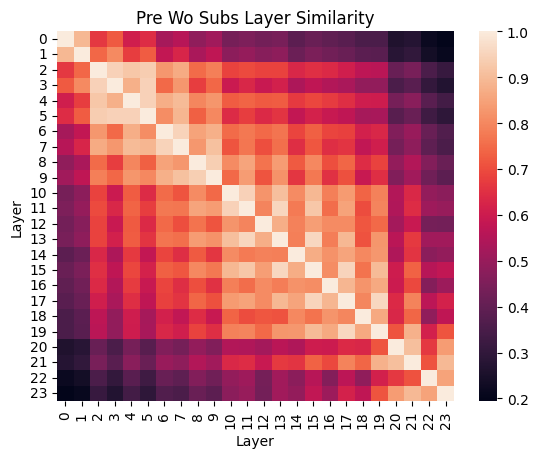

In [64]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [65]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity)

Similarity Scores: [0.89065987, 0.74216765, 0.94643396, 0.8768072, 0.9442436, 0.8085895, 0.94920635, 0.8299519, 0.9389832, 0.74606264, 0.94641286, 0.79488325, 0.872364, 0.7857005, 0.86983263, 0.810721, 0.88872576, 0.7981166, 0.86449146, 0.71150386, 0.9079738, 0.7092871, 0.85170376]
Number of High Similar Pairs: 16


In [66]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.89065987, 0.74216765, 0.94643396, 0.8768072, 0.9442436, 0.8085895, 0.94920635, 0.8299519, 0.9389832, 0.74606264, 0.94641286, 0.79488325, 0.872364, 0.7857005, 0.86983263, 0.810721, 0.88872576, 0.7981166, 0.86449146, 0.71150386, 0.9079738, 0.7092871, 0.85170376]
Number of High Similar Pairs: 13


In [67]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.89065987, 0.74216765, 0.94643396, 0.8768072, 0.9442436, 0.8085895, 0.94920635, 0.8299519, 0.9389832, 0.74606264, 0.94641286, 0.79488325, 0.872364, 0.7857005, 0.86983263, 0.810721, 0.88872576, 0.7981166, 0.86449146, 0.71150386, 0.9079738, 0.7092871, 0.85170376]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

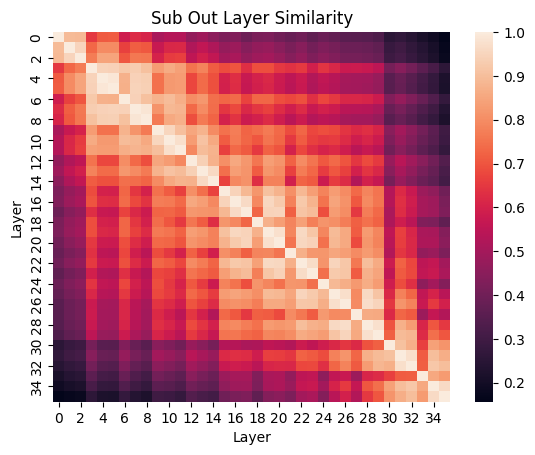

In [68]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [69]:
_,_ = adjacent_similarity_stats(sub_out_similarity)

Similarity Scores: [0.8924328, 0.9478675, 0.7672496, 0.94536054, 0.9892478, 0.8710462, 0.94378585, 0.9837653, 0.76336604, 0.95086026, 0.97322303, 0.7910449, 0.9400447, 0.95941174, 0.6696879, 0.9460384, 0.9605754, 0.72771114, 0.87183666, 0.9759699, 0.75555015, 0.86905557, 0.9669834, 0.74353814, 0.8890351, 0.97076416, 0.79880136, 0.86116254, 0.97585565, 0.7172938, 0.9072642, 0.97056556, 0.71648544, 0.8528039, 0.9605325]
Number of High Similar Pairs: 25


In [70]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.89065987, 0.74216765, 0.94643396, 0.8768072, 0.9442436, 0.8085895, 0.94920635, 0.8299519, 0.9389832, 0.74606264, 0.94641286, 0.79488325, 0.872364, 0.7857005, 0.86983263, 0.810721, 0.88872576, 0.7981166, 0.86449146, 0.71150386, 0.9079738, 0.7092871, 0.85170376]
Number of High Similar Pairs: 13


In [71]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.89065987, 0.74216765, 0.94643396, 0.8768072, 0.9442436, 0.8085895, 0.94920635, 0.8299519, 0.9389832, 0.74606264, 0.94641286, 0.79488325, 0.872364, 0.7857005, 0.86983263, 0.810721, 0.88872576, 0.7981166, 0.86449146, 0.71150386, 0.9079738, 0.7092871, 0.85170376]
Number of High Similar Pairs: 6


### Using Val Data on CLS Token only

In [72]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_pre_wo_similarity, val_sub_similarity, val_pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_pre_wo_stats = cka_eval.similarity_stats(val_pre_wo_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)
val_pre_wo_subs_stats = cka_eval.similarity_stats(val_pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {val_pre_wo_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {val_pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:53<00:00,  2.17it/s]

  Reps Similarity Stats:
    Average: 0.898509
    Highest: 0.946228
    Lowest:  0.816805

  Atts Similarity Stats:
    Average: 0.967940
    Highest: 0.995208
    Lowest:  0.901792
  MHA Similarity Stats:
    Average: 0.905318
    Highest: 0.958993
    Lowest:  0.796785
  Pre Wo Similarity Stats:
    Average: 0.784844
    Highest: 0.924522
    Lowest:  0.626694
  Sublayer Similarity Stats:
    Average: 0.937603
    Highest: 0.988663
    Lowest:  0.791765
  Pre Wo Sublayer Similarity Stats:
    Average: 0.846310
    Highest: 0.950906
    Lowest:  0.699617


In [73]:
val_sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

val_sub_out_stats = cka_eval.similarity_stats(val_sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {val_sub_out_stats['average']:.6f}")
print(f"    Highest: {val_sub_out_stats['max']:.6f}")
print(f"    Lowest:  {val_sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:38<00:00,  2.96it/s]

  Sub Out Similarity Stats:
    Average: 0.880533
    Highest: 0.988663
    Lowest:  0.667852


Text(50.722222222222214, 0.5, 'Layer')

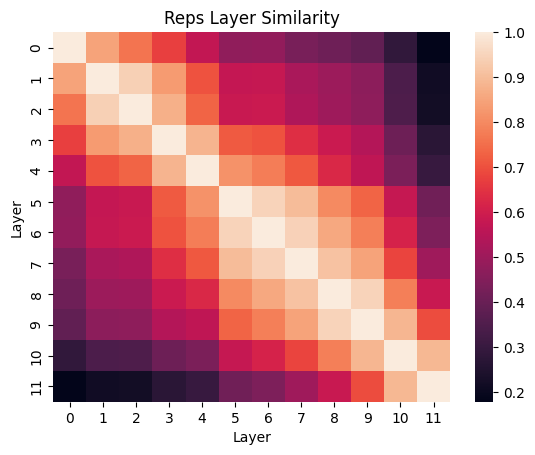

In [74]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [75]:
_,_ = adjacent_similarity_stats(val_reps_similarity)

Similarity Scores: [0.8471032, 0.93989056, 0.87256634, 0.8820188, 0.81680506, 0.9459825, 0.9433507, 0.9130052, 0.94622827, 0.88730836, 0.88934034]
Number of High Similar Pairs: 11


In [76]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.85)

Similarity Scores: [0.8471032, 0.93989056, 0.87256634, 0.8820188, 0.81680506, 0.9459825, 0.9433507, 0.9130052, 0.94622827, 0.88730836, 0.88934034]
Number of High Similar Pairs: 9


In [77]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.9)

Similarity Scores: [0.8471032, 0.93989056, 0.87256634, 0.8820188, 0.81680506, 0.9459825, 0.9433507, 0.9130052, 0.94622827, 0.88730836, 0.88934034]
Number of High Similar Pairs: 5


Text(50.722222222222214, 0.5, 'Layer')

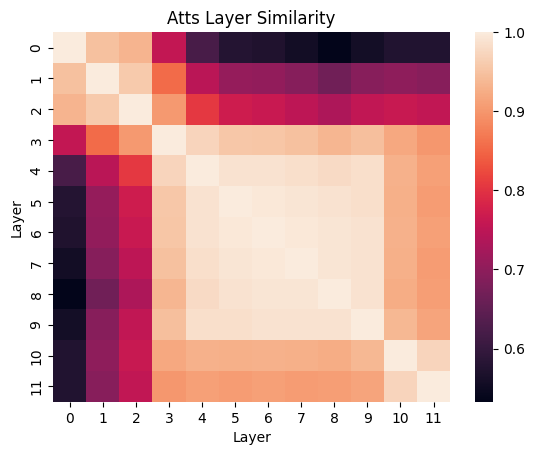

In [78]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [79]:
_,_ = adjacent_similarity_stats(val_atts_similarity)

Similarity Scores: [0.94873655, 0.95850056, 0.90179193, 0.97107357, 0.9879093, 0.995208, 0.99508363, 0.99188864, 0.988176, 0.9376255, 0.97134185]
Number of High Similar Pairs: 11


In [80]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.85)

Similarity Scores: [0.94873655, 0.95850056, 0.90179193, 0.97107357, 0.9879093, 0.995208, 0.99508363, 0.99188864, 0.988176, 0.9376255, 0.97134185]
Number of High Similar Pairs: 11


In [81]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.9)

Similarity Scores: [0.94873655, 0.95850056, 0.90179193, 0.97107357, 0.9879093, 0.995208, 0.99508363, 0.99188864, 0.988176, 0.9376255, 0.97134185]
Number of High Similar Pairs: 11


Text(50.722222222222214, 0.5, 'Layer')

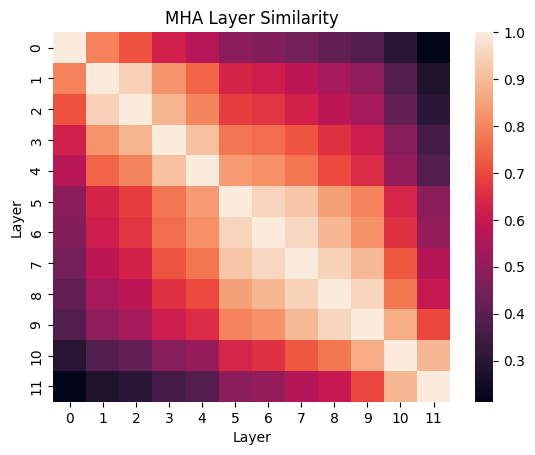

In [82]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [83]:
_,_ = adjacent_similarity_stats(val_mha_similarity)

Similarity Scores: [0.7967851, 0.9453372, 0.8886944, 0.91173774, 0.8382003, 0.9519029, 0.9589932, 0.9482632, 0.9565171, 0.8710205, 0.891051]
Number of High Similar Pairs: 10


In [84]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.85)

Similarity Scores: [0.7967851, 0.9453372, 0.8886944, 0.91173774, 0.8382003, 0.9519029, 0.9589932, 0.9482632, 0.9565171, 0.8710205, 0.891051]
Number of High Similar Pairs: 9


In [85]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.9)

Similarity Scores: [0.7967851, 0.9453372, 0.8886944, 0.91173774, 0.8382003, 0.9519029, 0.9589932, 0.9482632, 0.9565171, 0.8710205, 0.891051]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

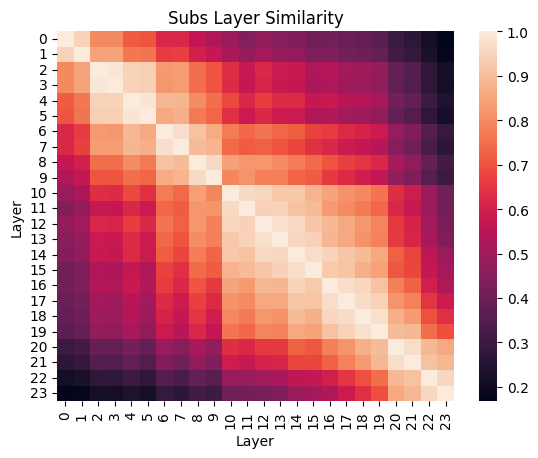

In [86]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [87]:
_,_ = adjacent_similarity_stats(val_sub_similarity)

Similarity Scores: [0.9456416, 0.8468846, 0.98866284, 0.9457844, 0.9840549, 0.8576614, 0.9715254, 0.89638036, 0.9589739, 0.79176456, 0.9598142, 0.94352216, 0.97623783, 0.95643944, 0.96781737, 0.9260857, 0.9697695, 0.9674982, 0.9753159, 0.8974421, 0.97071004, 0.9114011, 0.95547473]
Number of High Similar Pairs: 22


In [88]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.85)

Similarity Scores: [0.9456416, 0.8468846, 0.98866284, 0.9457844, 0.9840549, 0.8576614, 0.9715254, 0.89638036, 0.9589739, 0.79176456, 0.9598142, 0.94352216, 0.97623783, 0.95643944, 0.96781737, 0.9260857, 0.9697695, 0.9674982, 0.9753159, 0.8974421, 0.97071004, 0.9114011, 0.95547473]
Number of High Similar Pairs: 21


In [89]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.9)

Similarity Scores: [0.9456416, 0.8468846, 0.98866284, 0.9457844, 0.9840549, 0.8576614, 0.9715254, 0.89638036, 0.9589739, 0.79176456, 0.9598142, 0.94352216, 0.97623783, 0.95643944, 0.96781737, 0.9260857, 0.9697695, 0.9674982, 0.9753159, 0.8974421, 0.97071004, 0.9114011, 0.95547473]
Number of High Similar Pairs: 18


Text(50.722222222222214, 0.5, 'Layer')

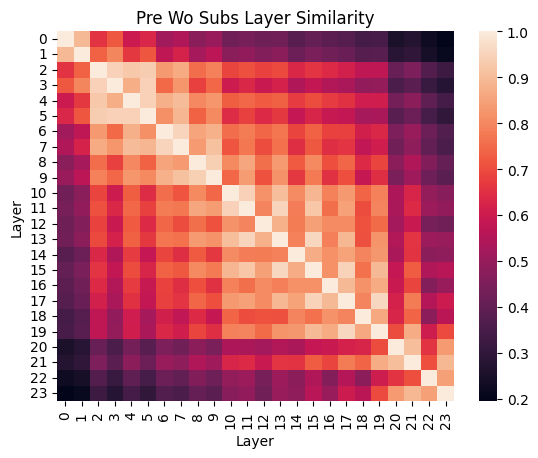

In [90]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [91]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity)

Similarity Scores: [0.89539045, 0.7350665, 0.9451464, 0.8738311, 0.94443864, 0.81166255, 0.9509061, 0.833534, 0.9396769, 0.7435578, 0.9459723, 0.79363495, 0.87775856, 0.7862005, 0.87067425, 0.81445664, 0.89319843, 0.79406667, 0.8647054, 0.6996169, 0.90538734, 0.70150477, 0.84474045]
Number of High Similar Pairs: 16


In [92]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.89539045, 0.7350665, 0.9451464, 0.8738311, 0.94443864, 0.81166255, 0.9509061, 0.833534, 0.9396769, 0.7435578, 0.9459723, 0.79363495, 0.87775856, 0.7862005, 0.87067425, 0.81445664, 0.89319843, 0.79406667, 0.8647054, 0.6996169, 0.90538734, 0.70150477, 0.84474045]
Number of High Similar Pairs: 12


In [93]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.89539045, 0.7350665, 0.9451464, 0.8738311, 0.94443864, 0.81166255, 0.9509061, 0.833534, 0.9396769, 0.7435578, 0.9459723, 0.79363495, 0.87775856, 0.7862005, 0.87067425, 0.81445664, 0.89319843, 0.79406667, 0.8647054, 0.6996169, 0.90538734, 0.70150477, 0.84474045]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

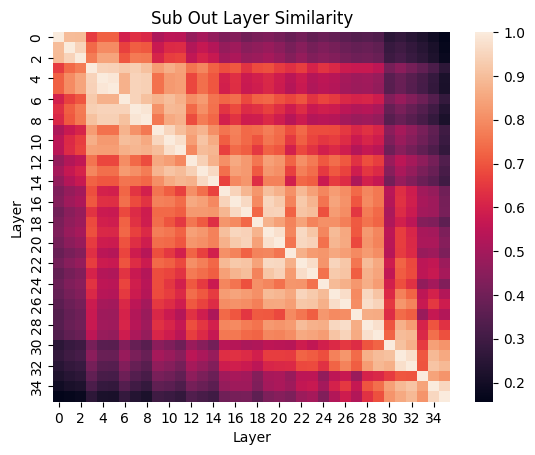

In [94]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [95]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity)

Similarity Scores: [0.89539045, 0.9456416, 0.7683846, 0.9451464, 0.98866284, 0.87151295, 0.94443864, 0.9840549, 0.7598595, 0.9509061, 0.9715254, 0.7911336, 0.9396769, 0.9589739, 0.6678518, 0.9459723, 0.9598142, 0.73056054, 0.87775856, 0.97623783, 0.7544109, 0.87067425, 0.96781737, 0.7482095, 0.89319843, 0.9697695, 0.79985976, 0.8647054, 0.9753159, 0.7250151, 0.90538734, 0.97071004, 0.6998607, 0.84474045, 0.95547473]
Number of High Similar Pairs: 25


In [96]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.85)

Similarity Scores: [0.89539045, 0.9456416, 0.7683846, 0.9451464, 0.98866284, 0.87151295, 0.94443864, 0.9840549, 0.7598595, 0.9509061, 0.9715254, 0.7911336, 0.9396769, 0.9589739, 0.6678518, 0.9459723, 0.9598142, 0.73056054, 0.87775856, 0.97623783, 0.7544109, 0.87067425, 0.96781737, 0.7482095, 0.89319843, 0.9697695, 0.79985976, 0.8647054, 0.9753159, 0.7250151, 0.90538734, 0.97071004, 0.6998607, 0.84474045, 0.95547473]
Number of High Similar Pairs: 24


In [97]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.9)

Similarity Scores: [0.89539045, 0.9456416, 0.7683846, 0.9451464, 0.98866284, 0.87151295, 0.94443864, 0.9840549, 0.7598595, 0.9509061, 0.9715254, 0.7911336, 0.9396769, 0.9589739, 0.6678518, 0.9459723, 0.9598142, 0.73056054, 0.87775856, 0.97623783, 0.7544109, 0.87067425, 0.96781737, 0.7482095, 0.89319843, 0.9697695, 0.79985976, 0.8647054, 0.9753159, 0.7250151, 0.90538734, 0.97071004, 0.6998607, 0.84474045, 0.95547473]
Number of High Similar Pairs: 18


### Using Training Data using Whole Sequence

In [98]:
reps_similarity, atts_similarity, mha_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:12<00:00,  1.58it/s]


ValueError: too many values to unpack (expected 4)

In [ ]:
reps_similarity, atts_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

In [ ]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Val Data using Whole Sequence

In [ ]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

In [ ]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Training Data for Heads Redundancy

In [ ]:
headsCka_eval

In [ ]:
outputs.attentions['attention_head'][0].shape

In [ ]:
outputs.attentions['attention_head'][11].shape

In [ ]:
from CKA import CudaCKA

In [ ]:
from tqdm import tqdm

In [ ]:
class TestHeadRedundancyEval:
    def __init__(self, device):
        self.cuda_cka = CudaCKA(device)
 
    def collect_selected_layer_head_matrices(self, atts, layer_indices):
        """
        atts: list of length L, each (batch, heads, seq_q, seq_k)
        layer_indices: which layers to include (e.g. [3], [0,1,2], or
                       None for all layers)
 
        Returns:
            matrices: list of (batch, seq_q, seq_k) tensors, UNFLATTENED.
                      Sentence-level CKA needs the (n, n) shape intact --
                      do not flatten these.
            labels: list of (layer_idx, head_idx) tuples, same order/length
                    as matrices. Required to interpret rows/cols of the
                    returned similarity matrix once more than one layer
                    is involved.
        """
        if layer_indices is None:
            layer_indices = [i for i in range(len(atts))]  # fixed: missing ')'
 
        matrices = []
        labels = []
        for layer_idx in layer_indices:
            layer_att = atts[layer_idx]  # (batch, heads, seq_q, seq_k)
            heads = layer_att.shape[1]
            for h in range(heads):
                matrices.append(layer_att[:, h, :, :])
                labels.append((layer_idx, h))
        return matrices, labels
 
    def _accumulate_batch(self, matrices, attention_mask, scores_accum):
        """
        Adds this batch's per-sentence CKA sums into scores_accum (in place)
        and returns how many valid sentences (n_valid >= 2) contributed.
 
        Diagonal entries are CKA(head_i, head_i) for each sentence, which
        is always exactly 1.0 -- so after normalizing by n_valid_sentences
        the diagonal stays exactly 1.0, guaranteed to be the max of every
        row/column. No special-casing needed for "same head = highest
        similarity"; it falls out of CKA's own definition as long as every
        (i, i) pair is computed the same way as every (i, j) pair below.
        """
        M = len(matrices)
        batch = matrices[0].shape[0]
        n_valid_sentences = 0
 
        with torch.no_grad():
            for b in range(batch):
                # Padding-side agnostic: works regardless of left/right padding.
                valid_idx = attention_mask[b].bool()
                n_valid = int(valid_idx.sum().item())
 
                # Guard against degenerate very-short sentences where
                # linear_CKA's variance terms can be ~0 -> NaN.
                if n_valid < 2:
                    continue
                n_valid_sentences += 1
 
                for i in range(M):
                    Ai = matrices[i][b][valid_idx][:, valid_idx]  # (n_valid, n_valid)
                    for j in range(i, M):
                        Bj = matrices[j][b][valid_idx][:, valid_idx]
                        val = self.cuda_cka.linear_CKA(Ai, Bj).detach()
                        scores_accum[i, j] += val
                        if i != j:
                            scores_accum[j, i] += val
                        # i == j case (diagonal): added once, correctly,
                        # via the scores_accum[i, j] += val line above.
 
        return n_valid_sentences
 
    def att_head_redundancy_estimate(self, model, dataloader, device,
                                      max_iter=float("Inf"), layer_indices=None,
                                      attention_mask_key="attention_mask"):
        """
        Runs sentence-level CKA head-redundancy estimation over an entire
        dataloader. Diagonal of the returned matrix is guaranteed to be
        1.0 (a head is always maximally similar to itself), so every
        row/column's max similarity is its own diagonal entry.
 
        Returns:
            scores: (M, M) numpy array, M = len(layer_indices or all)*heads
            labels: list of (layer_idx, head_idx), same order as rows/cols
        """
        model.set_use_module_grafting(False)
        model.set_use_scc_status(False)
 
        n_batch = len(dataloader)
        n_steps = min(n_batch, max_iter) if max_iter != float("Inf") else n_batch
        progress_bar = tqdm(range(n_steps), desc="CKA Sublayer Evaluation")
 
        model.eval()
 
        scores = None
        labels = None
        total_valid_sentences = 0
 
        for step, batch in enumerate(dataloader):
            if step == max_iter:
                break
 
            batch = {k: v.to(device) for k, v in batch.items()}
            attention_mask = batch[attention_mask_key]
 
            with torch.no_grad():
                output = model(**batch)
 
            atts = output.attentions["attention_head"]  # list of (batch, heads, seq_q, seq_k)
 
            matrices, labels = self.collect_selected_layer_head_matrices(atts, layer_indices)
 
            if scores is None:
                M = len(matrices)
                scores = torch.zeros(M, M, device=matrices[0].device)
 
            n_valid = self._accumulate_batch(matrices, attention_mask, scores)
            total_valid_sentences += n_valid
 
            progress_bar.update(1)
 
        if total_valid_sentences == 0:
            scores.fill_(float("nan"))
        else:
            scores = scores / total_valid_sentences
 
        # Sanity: diagonal should be (numerically) 1.0 -- confirms the
        # "same head = highest similarity" property holds by construction.
        return scores.cpu().numpy(), labels

In [ ]:
test = TestHeadRedundancyEval(device)

In [ ]:
scores, labels = test.att_head_redundancy_estimate(model, train_dataloader, device, layer_indices=[10, 11], max_iter=5)

In [ ]:
for batch in train_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    attention_mask = batch['attention_mask']
    with torch.no_grad():
        output = model(**batch)
    break
{k: v.shape for k, v in batch.items()}

In [ ]:
len(outputs.attentions['attention_head'])

In [ ]:
outputs.attentions['attention_head'][0].shape

In [ ]:
matrices, labels = test.collect_selected_layer_head_matrices(outputs.attentions['attention_head'], [0, 1])

In [ ]:
labels

In [ ]:
len(matrices)

In [ ]:
matrices[0].shape

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sn

In [ ]:
title = "Atts Heads Similarity"
plt.title(title)
sn.heatmap(data = scores)
plt.xlabel("Heads")
plt.ylabel("Heads")

# 6. Sensitivity Score Analysis

In [99]:
from structure_prune_helper import register_importance_masks

In [100]:
register_importance_masks(
    model, device, register_pre_wo_layer=True, register_mha=True, register_mlp=True, register_mha_layer=True, register_mlp_layer=True
)

  Layer 0: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 1: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 2: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 3: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 4: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 5: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 6: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 7: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 8: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 9: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 10: Register

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [101]:
from structure_prune_helper import compute_layer_importance_scores

In [102]:
pre_wo_importance, mha_importance, ffn_importance, head_importance, neuron_importance, sublayer_importance =compute_layer_importance_scores(
    model, train_dataloader, device, max_batches=115,
    compute_mha=True, compute_ffn=True, compute_heads=True,
    compute_neurons=True, compute_pre_wo=True,
    display_separate=True, display_combined=True, display_pruning_order=True,
)

Computing importance (pre-WO layer, MHA layer, FFN layer, heads, neurons): 100%|██████████| 115/115 [00:14<00:00,  7.89it/s]


Layer Importance Summary (separate):
          Layer  Pre-WO(layer)     MHA(layer)     FFN(layer)    Heads(mean)  Neurons(mean)
  ------------------------------------------------------------------------------------------
  0                     0.8315         0.8186         0.7925         0.0000         0.0000
  1                     0.8299         0.8198         0.8506         0.0000         0.0000
  2                     1.0000         1.0000         1.0000         0.0000         0.0000
  3                     0.8879         0.8977         0.9900         0.0000         0.0000
  4                     0.8382         0.8756         0.8913         0.0000         0.0000
  5                     0.9363         0.9595         0.9691         0.0000         0.0000
  6                     0.9708         0.9778         0.9976         0.0000         0.0000
  7                     0.7758         0.8154         0.9502         0.0000         0.0000
  8                     0.8891         0.8733     

In [103]:
pre_wo_importance

array([0.8315211 , 0.82992244, 1.        , 0.88786465, 0.83825   ,
       0.9363413 , 0.97084147, 0.775756  , 0.88908714, 0.9315482 ,
       0.9239526 , 0.7562013 ], dtype=float32)

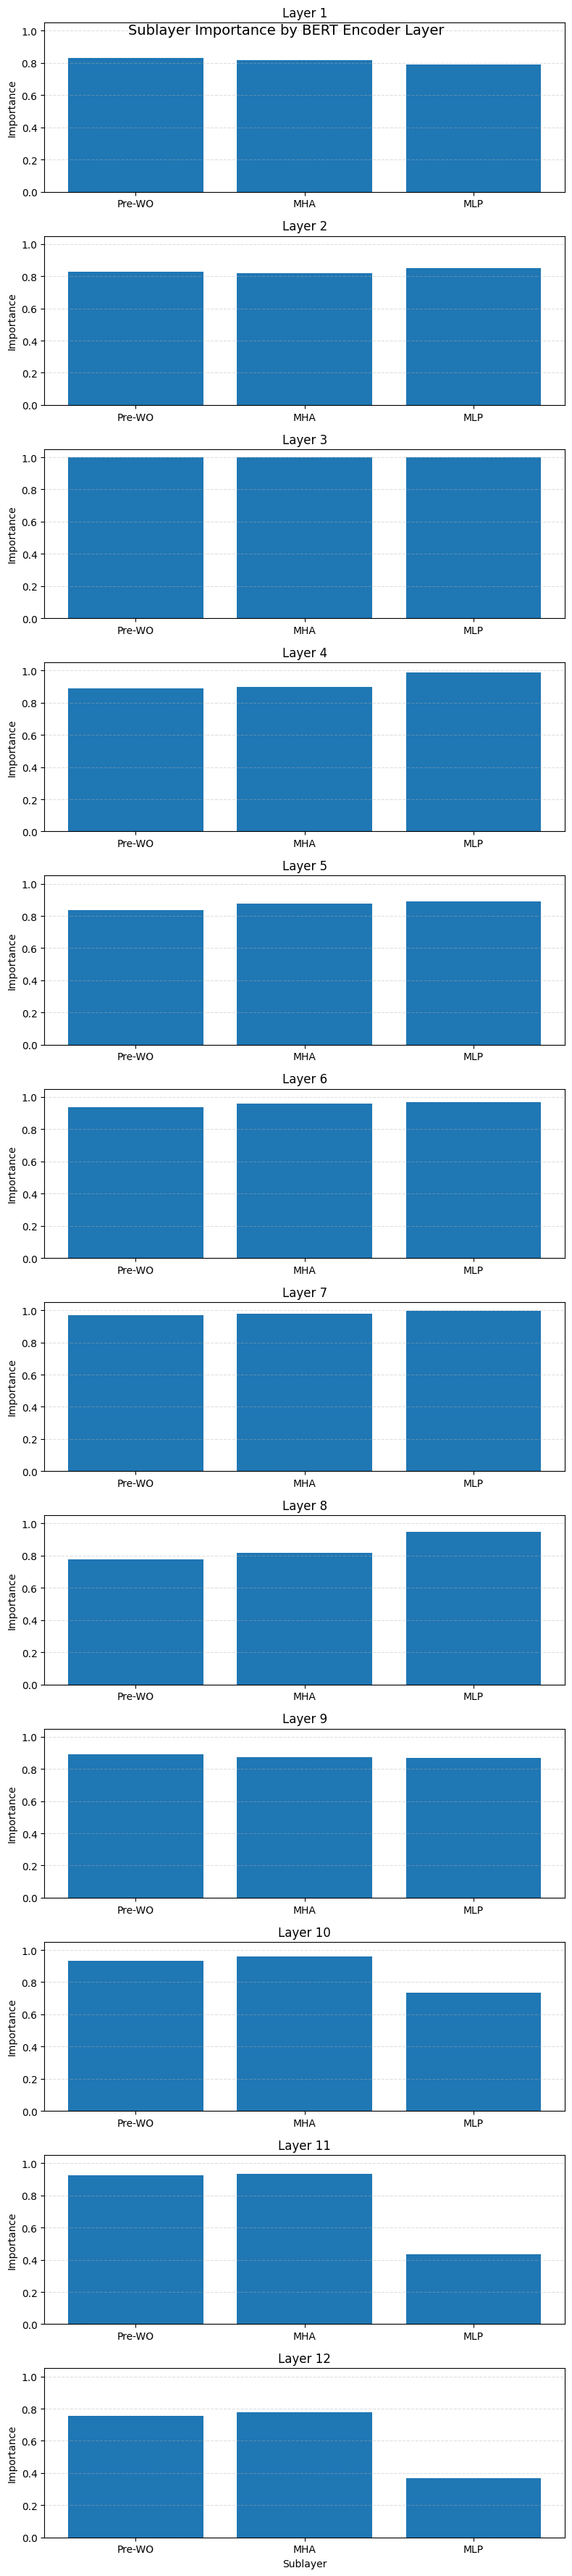

In [104]:
import matplotlib.pyplot as plt
import numpy as np

# Importance scores returned by compute_layer_importance_scores()
# pre_wo_importance, mha_importance, ffn_importance

n_layers = len(pre_wo_importance)

fig, axes = plt.subplots(
    n_layers, 1,
    figsize=(8, 3 * n_layers),
    sharey=True
)

# Handle the case of a model with only one layer
if n_layers == 1:
    axes = [axes]

labels = ["Pre-WO", "MHA", "MLP"]

for layer_idx, ax in enumerate(axes):
    scores = [
        pre_wo_importance[layer_idx],
        mha_importance[layer_idx],
        ffn_importance[layer_idx],
    ]

    ax.bar(labels, scores)
    ax.set_title(f"Layer {layer_idx + 1}")
    ax.set_ylabel("Importance")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Sublayer")
fig.suptitle("Sublayer Importance by BERT Encoder Layer", fontsize=14)
plt.tight_layout()
plt.show()

### Using Training Data on CLS Token only

In [105]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:53<00:00,  2.14it/s]

  Reps Similarity Stats:
    Average: 0.899399
    Highest: 0.949096
    Lowest:  0.815126

  Atts Similarity Stats:
    Average: 0.967805
    Highest: 0.995077
    Lowest:  0.902282
  MHA Similarity Stats:
    Average: 0.905886
    Highest: 0.959412
    Lowest:  0.792658
  Pre Wo Similarity Stats:
    Average: 0.785904
    Highest: 0.924022
    Lowest:  0.624771
  Sublayer Similarity Stats:
    Average: 0.938154
    Highest: 0.988536
    Lowest:  0.791573
  Pre Wo Sublayer Similarity Stats:
    Average: 0.846718
    Highest: 0.950487
    Lowest:  0.701380


In [106]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:39<00:00,  2.91it/s]

  Sub Out Similarity Stats:
    Average: 0.881107
    Highest: 0.989382
    Lowest:  0.666924


In [107]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

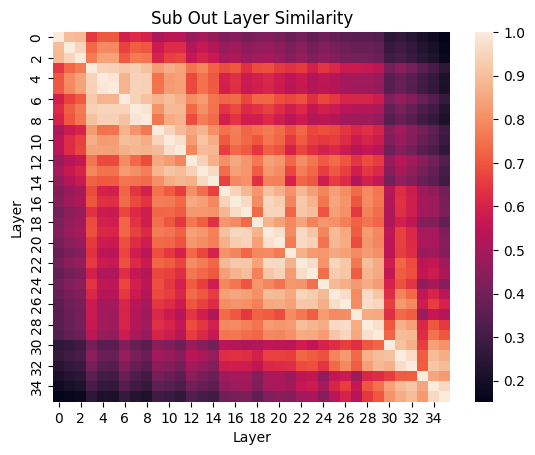

In [108]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [109]:
sub_out_similarity.shape 

(36, 36)

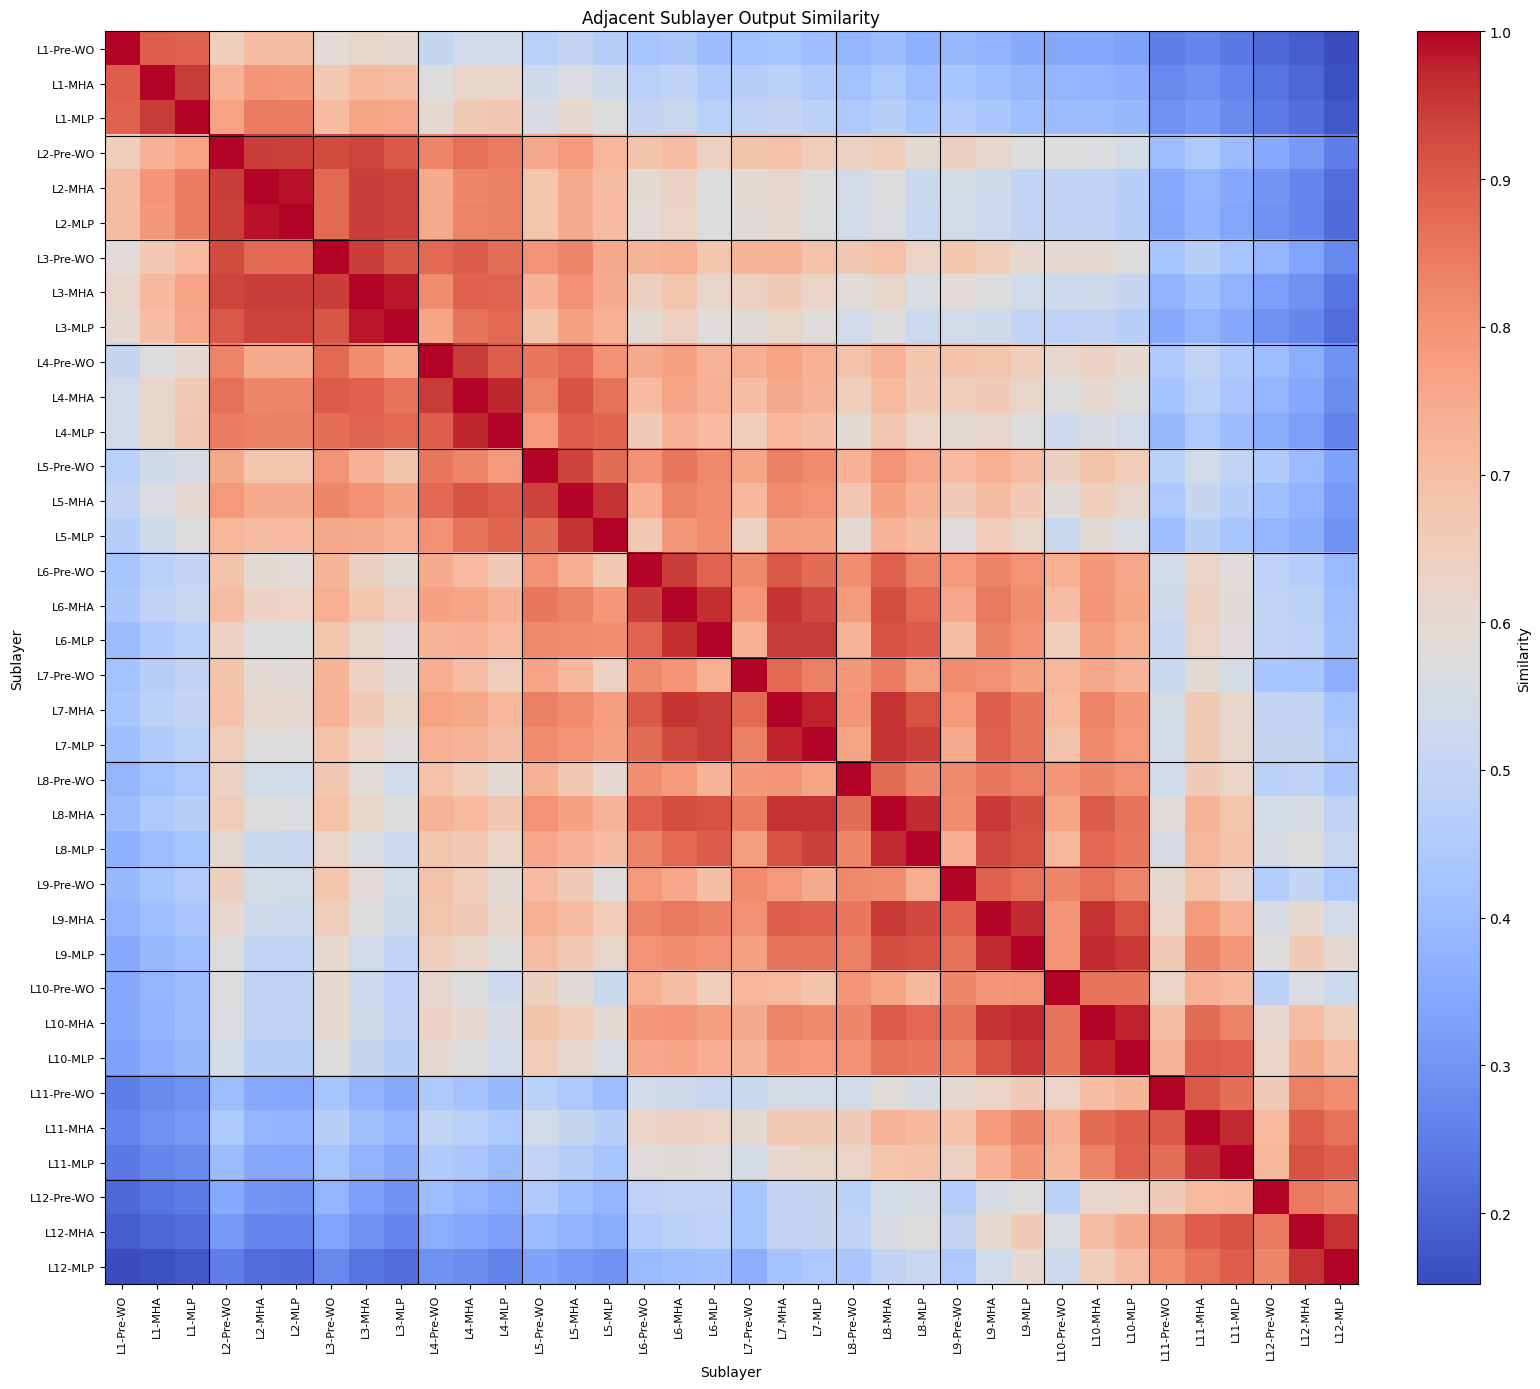

In [110]:
import matplotlib.pyplot as plt
import numpy as np

# sub_out_similarity: (36, 36)
n_layers = 12
sublayers = ["Pre-WO", "MHA", "MLP"]

labels = [
    f"L{layer + 1}-{sub}"
    for layer in range(n_layers)
    for sub in sublayers
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    sub_out_similarity,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="equal"
)

# Label every sublayer
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

# Add boundaries between encoder layers
for boundary in range(3, n_layers * 3, 3):
    ax.axhline(boundary - 0.5, color="black", linewidth=0.8)
    ax.axvline(boundary - 0.5, color="black", linewidth=0.8)

# Color scale
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Similarity")

ax.set_title("Adjacent Sublayer Output Similarity")
ax.set_xlabel("Sublayer")
ax.set_ylabel("Sublayer")

plt.tight_layout()
plt.show()